# Results and Discussion
Assessing Probability Reliability under Class Prior Shift: The Effects of Imbalance Handling and Calibration in Online Purchase Prediction.

This notebook presents a conservative descriptive empirical evaluation. Thirty overlapping splits measure sensitivity to splitting one dataset. No population significance tests or confidence intervals are used. Raw + Prior is exploratory. The prospective freeze chronology remains inconclusive. All exports are written to `notebooks/outputs/`.

## 0 — Setup and Data Integrity

In [1]:
from pathlib import Path
import hashlib, json, sys, platform, importlib.metadata as metadata
import itertools
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from matplotlib.ticker import FormatStrFormatter

def find_root():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / 'confirmatory_protocol_v2.json').is_file() and (candidate / 'outputs_confirmatory_30_seeds').is_dir():
            return candidate
    raise FileNotFoundError('Run from the repository root or any directory beneath it.')
ROOT = find_root()
OUT = ROOT / 'notebooks' / 'outputs'
OUT.mkdir(parents=True, exist_ok=True)
paths = [
 'outputs_confirmatory_30_seeds/all_repetitions.csv',
 'outputs_confirmatory_30_seeds/aggregate_summary.csv',
 'outputs_confirmatory_30_seeds/training_metadata.csv',
 'outputs_confirmatory_30_seeds/all_audits.csv',
 'scientific_validation_followup/METRIC_RECOMPUTATION.csv',
 'scientific_validation_followup/PREDICTION_LEVEL_VALIDATION.md',
 'scientific_validation_followup/STATISTICAL_INFERENCE_VALIDITY.md',
 'scientific_validation_followup/FINAL_SCIENTIFIC_VALIDITY_DECISION.md',
 'confirmatory_protocol_v2.json', 'confirmatory_protocol_freeze_v2.json',
 'outputs_confirmatory_30_seeds/dataset_provenance.json',
 'online_shoppers_intention.csv', 'outputs_confirmatory_30_seeds/output_hashes.json']
for path in paths:
    assert (ROOT/path).is_file(), f'Missing dependency: {path}'
def sha(path): return hashlib.sha256(path.read_bytes()).hexdigest()
input_hashes = {p: sha(ROOT/p) for p in paths}
df, aggregate, training, audits, verified = [pd.read_csv(ROOT/p) for p in paths[:5]]
protocol = json.loads((ROOT/'confirmatory_protocol_v2.json').read_text())
cfg = protocol['effective_config']
dataset = pd.read_csv(ROOT/'online_shoppers_intention.csv')
provenance = json.loads((ROOT/'outputs_confirmatory_30_seeds/dataset_provenance.json').read_text())
assert sha(ROOT/'online_shoppers_intention.csv') == protocol['dataset_sha256']
keys = ['seed','imbalance_strategy','calibration','target_prevalence','prior_correction']
metrics = ['brier_score','log_loss','ece','average_precision','f1']
required = keys + metrics + ['sample_id_sha256','n_test','n_positive','n_negative','actual_prevalence','source_prevalence']
assert set(required) <= set(df.columns)
assert not df[required].isna().any().any()
assert np.isfinite(df[metrics].to_numpy()).all()
assert all(df[m].between(0,1).all() for m in ['brier_score','ece','average_precision','f1'])
assert df.log_loss.ge(0).all()
assert df.prior_correction.dtype == bool
expected = set(itertools.product(cfg['seeds'],cfg['imbalance_strategies'],cfg['calibration_methods'],cfg['prevalences'],[False,True]))
observed = set(df[keys].itertuples(index=False,name=None))
assert observed == expected and len(df) == len(expected) and not df.duplicated(keys).any()
assert set(df.seed) == set(range(42,72))
assert (df.n_positive + df.n_negative == df.n_test).all()
assert np.allclose(df.actual_prevalence,df.n_positive/df.n_test,atol=1e-15)
assert df.groupby(['seed','target_prevalence']).sample_id_sha256.nunique().eq(1).all()
assert len(training)==90 and not training.duplicated(['seed','strategy']).any()
assert training.base_converged.all() and training.platt_converged.all()
assert set(['audit_type','sample_id_sha256','unique_observations','n_total']) <= set(audits.columns)
shift = audits[audits.audit_type.eq('shift')]
assert len(shift)==90 and (shift.unique_observations==shift.n_total).all()
v = verified.rename(columns={'strategy':'imbalance_strategy'})
assert not v.duplicated(keys+['metric']).any() and len(v)==len(df)*3
long = df.melt(id_vars=keys,value_vars=metrics[:3],var_name='metric',value_name='original')
check = long.merge(v,on=keys+['metric'],validate='one_to_one')
assert len(check)==len(long)
assert check['match_atol_1e-12_rtol_1e-10'].eq(True).all()
assert np.allclose(check.original,check.reported,atol=1e-15,rtol=0)
assert np.isclose(check.original,check.computed,atol=1e-12,rtol=1e-10).all()
agg_check = df.groupby(keys[1:])[metrics[:3]].mean().reset_index().merge(aggregate,on=keys[1:],validate='one_to_one')
assert len(agg_check)==36
for metric in metrics[:3]: assert np.allclose(agg_check[metric],agg_check[metric+'_mean'],atol=1e-15)
frozen_manifest = json.loads((ROOT/'outputs_confirmatory_30_seeds/output_hashes.json').read_text())
for p,h in frozen_manifest['files'].items(): assert sha(ROOT/'outputs_confirmatory_30_seeds'/p)==h, p
display(pd.DataFrame({'check':['Expected / observed combinations','Seeds','Metric comparisons / mismatches','Frozen output hashes'], 'result':[f'{len(expected)} / {len(df)}',df.seed.nunique(),f'{len(check)} / 0',f"{len(frozen_manifest['files'])} matched"]}))
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False,'figure.facecolor':'white','savefig.dpi':350,'pdf.fonttype':42})
strategies = cfg['imbalance_strategies']
names = {'baseline':'Baseline','oversampling':'ROS','class_weight':'CW'}
colors = ['#0072B2','#D55E00','#009E73']
def note(text): display(Markdown(text))

,check,result
0,Expected / observed combinations,1080 / 1080
1,Seeds,30
2,Metric comparisons / mismatches,3240 / 0
3,Frozen output hashes,198 matched


## 1 — Experimental Results Overview
Table 1 describes the source dataset and the exact design. The nominal reference prevalence is distinguished from the observed source prevalence.

In [2]:
y = dataset[cfg['target']].astype(int)
splits = audits[audits.audit_type.eq('split')].groupby('split')['n'].agg(['min','max'])
items = {
 'Dataset':provenance['title'], 'Provenance':provenance['url'], 'DOI':provenance['doi'],
 'Dataset SHA-256':protocol['dataset_sha256'], 'Observations':len(dataset),
 'Positive class':int(y.sum()), 'Negative class':int((1-y).sum()),
 'Positive proportion':float(y.mean()), 'Predictors':len(dataset.columns)-1,
 'Train/calibration/test proportions':'0.60 / 0.20 / 0.20',
 'Train/calibration/test counts':' / '.join(str(int(splits.loc[s,'min'])) for s in ['train','calibration','test_original']),
 'Seeds':f"{len(cfg['seeds'])} (42–71)", 'Strategies':', '.join(names[s] for s in strategies),
 'Configurations':'Raw; Platt; Raw + Prior (exploratory); Platt + Prior',
 'Nominal target prevalences':str(cfg['prevalences']),
 'Realized scenario prevalences':str(df.groupby('target_prevalence').actual_prevalence.first().to_dict()),
 'Primary metric':'Brier score', 'Secondary metrics':'Log loss; 10-bin equal-width ECE',
 'Descriptive metrics':'Average precision; F1 at threshold 0.5',
 'Logistic Regression':str(cfg['model']), 'Platt input':cfg['platt']['input']}
table1 = pd.DataFrame(items.items(),columns=['item','value'])
display(table1)
overview = f"The dataset contains {len(dataset):,} observations and {len(dataset.columns)-1} predictors, with {int(y.sum()):,} positive outcomes ({y.mean():.6%}). The nominal 0.155 reference is distinct from the original prevalence {y.mean():.8f}. Each repeated evaluation uses the same 60/20/20 design; the 30 seeds are overlapping evaluations of one finite dataset."
note(overview)

,item,value
0,Dataset,Online Shoppers Purchasing Intention Dataset
1,Provenance,https://archive.ics.uci.edu/dataset/468/online...
2,DOI,10.24432/C5F88Q
3,Dataset SHA-256,b3055ee355f59134d851d32641183cb4a8b45def7124d2...
4,Observations,12330
5,Positive class,1908
6,Negative class,10422
7,Positive proportion,0.154745
8,Predictors,17
9,Train/calibration/test proportions,0.60 / 0.20 / 0.20


The dataset contains 12,330 observations and 17 predictors, with 1,908 positive outcomes (15.474453%). The nominal 0.155 reference is distinct from the original prevalence 0.15474453. Each repeated evaluation uses the same 60/20/20 design; the 30 seeds are overlapping evaluations of one finite dataset.

## 2 — Effects of Imbalance Handling
The main raw-probability comparison uses the nominal natural-prevalence reference. SD and range describe the observed split schedule; they are not population uncertainty estimates.

In [3]:
raw_reference = df[(df.calibration=='raw') & ~df.prior_correction & df.target_prevalence.eq(cfg['control_prevalence'])]
raw_summary = raw_reference.groupby('imbalance_strategy').brier_score.agg(['mean','std','median','min','max']).reindex(strategies)
raw_summary['difference_from_baseline'] = raw_summary['mean']-raw_summary.loc['baseline','mean']
display(raw_summary)
note('At the reference scenario, raw Brier scores were '+', '.join(f"{names[s]} {raw_summary.loc[s,'mean']:.6f}" for s in strategies)+'. Raw rebalancing was associated with larger probability error in this experiment. This observation does not imply that rebalancing is universally harmful. [CITATION NEEDED: imbalance handling and probability estimation.]')

,mean,std,median,min,max,difference_from_baseline
imbalance_strategy,,,,,,
baseline,0.085497,0.002330,0.085487,0.080873,0.090905,0.000000
oversampling,0.120614,0.003286,0.120417,0.114675,0.127131,0.035117
class_weight,0.120634,0.003092,0.119995,0.115176,0.125304,0.035137


At the reference scenario, raw Brier scores were Baseline 0.085497, ROS 0.120614, CW 0.120634. Raw rebalancing was associated with larger probability error in this experiment. This observation does not imply that rebalancing is universally harmful. [CITATION NEEDED: imbalance handling and probability estimation.]

## 3 — Effects of Probability Calibration
Table 2 includes all scenarios; Figure 1 uses the nominal 0.155 reference. Pairing includes seed and sample hash, with cardinality checked before any difference is computed.

,strategy,target_prevalence,n_pairs,raw_brier_score,platt_brier_score,raw_log_loss,platt_log_loss,raw_ece,platt_ece,mean_paired_brier_difference
0,baseline,0.100,30,0.064699,0.064756,0.240262,0.240310,0.042860,0.043837,0.000058
1,baseline,0.155,30,0.085497,0.085722,0.294588,0.294948,0.037969,0.038493,0.000225
2,baseline,0.250,30,0.121593,0.122106,0.389968,0.390702,0.073960,0.075469,0.000513
3,class_weight,0.100,30,0.119085,0.064666,0.444268,0.242252,0.210448,0.048042,-0.054419
4,class_weight,0.155,30,0.120634,0.085682,0.442600,0.296200,0.181019,0.047231,-0.034952
5,class_weight,0.250,30,0.123096,0.122125,0.441773,0.390905,0.130290,0.082328,-0.000972
6,oversampling,0.100,30,0.119007,0.064694,0.444115,0.242335,0.209867,0.048156,-0.054313
7,oversampling,0.155,30,0.120614,0.085732,0.442608,0.296380,0.180434,0.046916,-0.034882
8,oversampling,0.250,30,0.123180,0.122199,0.442073,0.391188,0.129740,0.081865,-0.000981


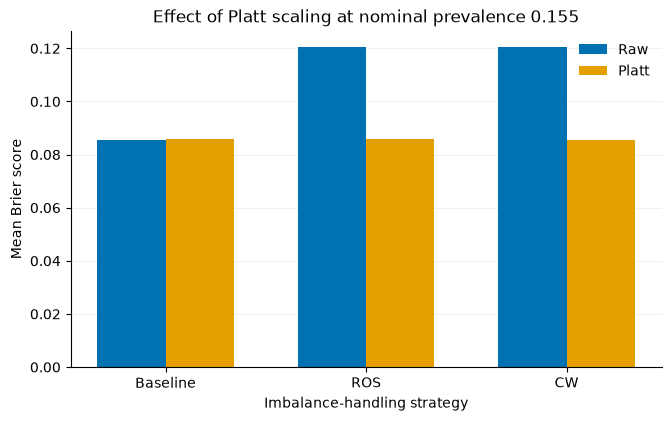

Figure 1. Mean Brier score for raw and Platt probabilities at nominal prevalence 0.155 across 30 overlapping splits. Lower values indicate better probabilistic accuracy; bars show means without inferential uncertainty intervals.

At the reference scenario, Platt minus Raw Brier changes were Baseline +0.000225, ROS -0.034882, CW -0.034952. Calibration substantially reduced the raw rebalancing differences. A separate natural calibration subset can adjust distorted probability scales, but finite-sample calibration remains imperfect. [CITATION NEEDED: sigmoid calibration.]

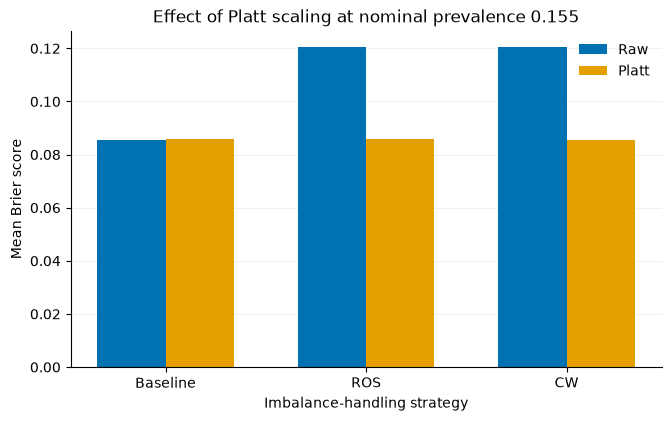

In [4]:
pairkeys = ['seed','imbalance_strategy','target_prevalence','sample_id_sha256']
def paired(a,b):
    result = a.merge(b,on=pairkeys,suffixes=('_a','_b'),validate='one_to_one')
    assert len(result)==len(a)==len(b)
    for c in ['n_test','n_positive','n_negative']:
        assert result[c+'_a'].equals(result[c+'_b'])
    return result
cal_pairs = paired(df[(df.calibration=='raw') & ~df.prior_correction],df[(df.calibration=='platt') & ~df.prior_correction])
rows=[]
for (strategy,prior),g in cal_pairs.groupby(['imbalance_strategy','target_prevalence']):
    r={'strategy':strategy,'target_prevalence':prior,'n_pairs':len(g)}
    for metric in metrics[:3]:
        r['raw_'+metric]=g[metric+'_a'].mean(); r['platt_'+metric]=g[metric+'_b'].mean()
    r['mean_paired_brier_difference']=(g.brier_score_b-g.brier_score_a).mean()
    rows.append(r)
table2=pd.DataFrame(rows)
display(table2)
ref=table2[table2.target_prevalence.eq(cfg['control_prevalence'])].set_index('strategy').reindex(strategies)
fig1,ax=plt.subplots(figsize=(6.6,4.1),layout='constrained')
x=np.arange(3); width=.34
ax.bar(x-width/2,ref.raw_brier_score,width,label='Raw',color='#0072B2')
ax.bar(x+width/2,ref.platt_brier_score,width,label='Platt',color='#E69F00')
ax.set(xticks=x,xticklabels=[names[s] for s in strategies],ylabel='Mean Brier score',xlabel='Imbalance-handling strategy',title='Effect of Platt scaling at nominal prevalence 0.155',ylim=(0,None))
ax.legend(frameon=False); ax.grid(axis='y',alpha=.18); ax.set_axisbelow(True)
display(fig1)
caption1='Figure 1. Mean Brier score for raw and Platt probabilities at nominal prevalence 0.155 across 30 overlapping splits. Lower values indicate better probabilistic accuracy; bars show means without inferential uncertainty intervals.'
note(caption1)
note('At the reference scenario, Platt minus Raw Brier changes were '+', '.join(f"{names[s]} {ref.loc[s,'mean_paired_brier_difference']:+.6f}" for s in strategies)+'. Calibration substantially reduced the raw rebalancing differences. A separate natural calibration subset can adjust distorted probability scales, but finite-sample calibration remains imperfect. [CITATION NEEDED: sigmoid calibration.]')

## 4 — Effects of Prior Probability Correction
The primary descriptive comparison is Platt + Prior versus Platt. Delta Brier is corrected minus uncorrected: negative values indicate improvement. Relative change is 100 × mean paired difference / mean uncorrected Brier. No p-values enter Table 3.

,strategy,target_prevalence,n_pairs,mean_brier_platt,mean_brier_platt_prior,mean_paired_difference,relative_change_percent,sd_paired_difference,median_paired_difference,seeds_improved,seeds_worsened,seeds_unchanged
0,baseline,0.10,30,0.064756,0.064748,-0.000008,-0.012757,0.000648,-0.000082,16,14,0
1,baseline,0.25,30,0.122106,0.111718,-0.010388,-8.507325,0.001415,-0.010433,30,0,0
2,class_weight,0.10,30,0.064666,0.064975,0.000309,0.477486,0.000611,0.000295,11,19,0
3,class_weight,0.25,30,0.122125,0.111037,-0.011088,-9.079093,0.001317,-0.011265,30,0,0
4,oversampling,0.10,30,0.064694,0.064996,0.000303,0.467974,0.000601,0.000308,11,19,0
5,oversampling,0.25,30,0.122199,0.111141,-0.011059,-9.049870,0.001308,-0.011200,30,0,0


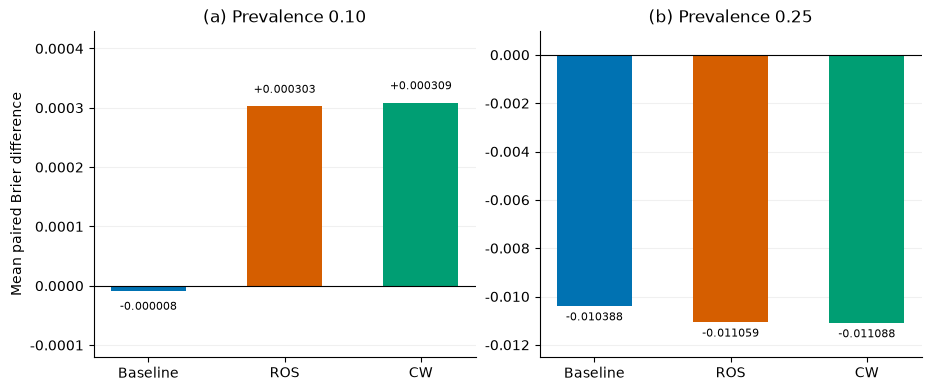

Figure 2. Mean paired Brier difference (Platt + Prior minus Platt) across 30 overlapping splits. Negative values indicate improvement. No population confidence intervals are shown.

At target 0.10, Baseline changed by -0.000008 (-0.01%), with 16/30 splits improving; CW changed by +0.000309 (+0.48%), with 11/30 splits improving; ROS changed by +0.000303 (+0.47%), with 11/30 splits improving. At target 0.25, Baseline changed by -0.010388 (-8.51%), with 30/30 splits improving; CW changed by -0.011088 (-9.08%), with 30/30 splits improving; ROS changed by -0.011059 (-9.05%), with 30/30 splits improving. Effect magnitude and split-wise consistency do not establish statistical significance or universal superiority.

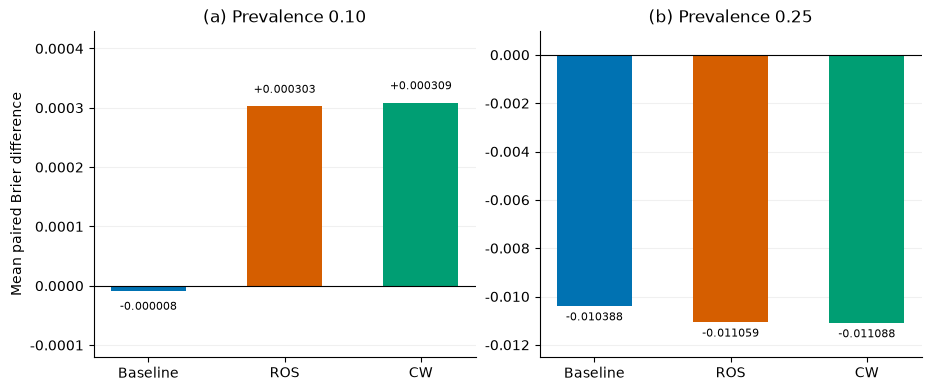

In [5]:
primary=df[df.calibration.eq('platt') & df.target_prevalence.isin(cfg['primary_prevalences'])]
prior_pairs=paired(primary[~primary.prior_correction],primary[primary.prior_correction])
rows=[]
secondary_rows=[]
for (strategy,prior),g in prior_pairs.groupby(['imbalance_strategy','target_prevalence']):
    d=g.brier_score_b-g.brier_score_a
    rows.append({'strategy':strategy,'target_prevalence':prior,'n_pairs':len(g),
      'mean_brier_platt':g.brier_score_a.mean(),'mean_brier_platt_prior':g.brier_score_b.mean(),
      'mean_paired_difference':d.mean(),'relative_change_percent':100*d.mean()/g.brier_score_a.mean(),
      'sd_paired_difference':d.std(ddof=1),'median_paired_difference':d.median(),
      'seeds_improved':int((d<0).sum()),'seeds_worsened':int((d>0).sum()),'seeds_unchanged':int((d==0).sum())})
    for metric in metrics[:3]:
        delta=(g[metric+'_b']-g[metric+'_a']).mean()
        secondary_rows.append({'strategy':strategy,'target_prevalence':prior,'metric':metric,'mean_delta':delta,'agrees_with_brier':bool(np.sign(delta)==np.sign(d.mean()))})
table3=pd.DataFrame(rows)
assert table3.n_pairs.eq(30).all() and len(table3)==6
display(table3)

fig2, axes = plt.subplots(
    1, 2,
    figsize=(9.2, 3.8),
    layout='constrained'
)

prevalences = [0.10, 0.25]

for ax, prevalence in zip(axes, prevalences):
    subset = (
        table3[table3['target_prevalence'].eq(prevalence)]
        .set_index('strategy')
        .reindex(strategies)
    )

    values = subset['mean_paired_difference'].to_numpy()
    x = np.arange(len(strategies))

    bars = ax.bar(
        x,
        values,
        width=0.55,
        color=colors[:len(strategies)]
    )

    ax.axhline(0, color='black', linewidth=0.8)

    ax.set_xticks(x)
    ax.set_xticklabels([names[s] for s in strategies])
    ax.set_title(f'({ "a" if prevalence == 0.10 else "b" }) Prevalence {prevalence:.2f}')

    # Separate Y-axis ranges for each prevalence
    if prevalence == 0.10:
        ax.set_ylim(-0.00012, 0.00043)
        ax.yaxis.set_major_formatter(FormatStrFormatter('%.4f'))
        label_offset = 0.000018
    else:
        ax.set_ylim(-0.0125, 0.001)
        ax.yaxis.set_major_formatter(FormatStrFormatter('%.3f'))
        label_offset = 0.00025

    for bar, value in zip(bars, values):
        y = value + label_offset if value >= 0 else value - label_offset

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            y,
            f'{value:+.6f}',
            ha='center',
            va='bottom' if value >= 0 else 'top',
            fontsize=8
        )

    ax.grid(axis='y', alpha=0.18)
    ax.set_axisbelow(True)

axes[0].set_ylabel('Mean paired Brier difference')

display(fig2)

caption2='Figure 2. Mean paired Brier difference (Platt + Prior minus Platt) across 30 overlapping splits. Negative values indicate improvement. No population confidence intervals are shown.'
note(caption2)
prior_text=[]
for p,g in table3.groupby('target_prevalence'):
    prior_text.append(f"At target {p:.2f}, "+'; '.join(f"{names[r.strategy]} changed by {r.mean_paired_difference:+.6f} ({r.relative_change_percent:+.2f}%), with {r.seeds_improved}/30 splits improving" for r in g.itertuples())+'.')
note(' '.join(prior_text)+' Effect magnitude and split-wise consistency do not establish statistical significance or universal superiority.')

## 5 — Secondary Metric Analysis
Log loss and ECE assess additional aspects of prediction quality. ECE depends on the chosen bins and is not a decomposition of the Brier score.

In [6]:
secondary=pd.DataFrame(secondary_rows)
display(secondary)
disagreement=secondary[~secondary.agrees_with_brier]
note('Metric direction disagreements: '+('; '.join(f"{names[r.strategy]}, target {r.target_prevalence:.2f}, {r.metric}: mean change {r.mean_delta:+.6f}" for r in disagreement.itertuples()) or 'none')+'. Lower binned ECE does not guarantee lower Brier score. Brier score measures squared probability error, while ECE compresses discrepancies into bin averages. Log loss penalizes confident errors more strongly. [CITATION NEEDED: proper scoring rules and ECE limitations.]')

,strategy,target_prevalence,metric,mean_delta,agrees_with_brier
0,baseline,0.10,brier_score,-0.000008,True
1,baseline,0.10,log_loss,-0.008388,True
2,baseline,0.10,ece,-0.013950,True
3,baseline,0.25,brier_score,-0.010388,True
4,baseline,0.25,log_loss,-0.019305,True
5,baseline,0.25,ece,-0.023374,True
6,class_weight,0.10,brier_score,0.000309,True
7,class_weight,0.10,log_loss,-0.008426,False
8,class_weight,0.10,ece,-0.013326,False
9,class_weight,0.25,brier_score,-0.011088,True


Metric direction disagreements: CW, target 0.10, log_loss: mean change -0.008426; CW, target 0.10, ece: mean change -0.013326; ROS, target 0.10, log_loss: mean change -0.008437; ROS, target 0.10, ece: mean change -0.013827. Lower binned ECE does not guarantee lower Brier score. Brier score measures squared probability error, while ECE compresses discrepancies into bin averages. Log loss penalizes confident errors more strongly. [CITATION NEEDED: proper scoring rules and ECE limitations.]

## 6 — Discussion and Limitations
Raw probability quality depended on imbalance handling, and the observed effects changed after Platt scaling. Calibration reduced much of the raw probability error for ROS and CW. Prior correction after calibration was prevalence dependent: the high-prevalence scenario showed consistent improvements, whereas low-prevalence Brier changes were small and could disagree with ECE or log loss.

For purchase prediction, these findings support checking probability accuracy after rebalancing and after a shift in prevalence. They do not demonstrate a universally superior strategy or automatic production transportability. [CITATION NEEDED: probability quality in decision making.]

The analysis uses one dataset and Logistic Regression. Shift was simulated through class-conditional test subsampling, with oracle knowledge of realized target prevalence. Stability of class-conditional features and availability of a valid target-prior estimate in production were not established. Repeated splits overlap; their standard deviations and sign counts characterize this split schedule, not population uncertainty. The freeze chronology remains inconclusive, so prospective preregistration is not claimed. AP and F1 are descriptive only; the exploratory Raw + Prior branch is excluded from the primary paired analysis.

## 7 — Export and Final Validation
All numeric exports are recalculated from the verified per-seed records. The final cell checks reopened tables, generated figures, input hashes, and dependency versions.

In [7]:
tables={
 'table_1_dataset_experiment_configuration.csv':table1,
 'table_2_imbalance_calibration_performance.csv':table2,
 'table_3_prior_correction_effects.csv':table3,
 'supporting_raw_reference_descriptive.csv':raw_summary.reset_index(),
 'supporting_secondary_metric_directions.csv':secondary}
for name,table in tables.items():
    table.to_csv(OUT/name,index=False)
    reopened=pd.read_csv(OUT/name)
    assert list(reopened.columns)==list(table.columns) and len(reopened)==len(table)
    for col in table.select_dtypes(include='number').columns:
        assert np.allclose(reopened[col],table[col],atol=1e-12,rtol=1e-10)
for stem,fig in [('figure_1_platt_calibration_effect',fig1),('figure_2_prior_correction_effect',fig2)]:
    for ext in ['pdf','png']:
        fig.savefig(OUT/f'{stem}.{ext}',dpi=350,bbox_inches='tight',facecolor='white')
        assert (OUT/f'{stem}.{ext}').stat().st_size>1000
    image=plt.imread(OUT/f'{stem}.png')
    assert image.shape[0]>1000 and np.std(image[:,:,:3])>.01
paragraphs=[
 ('Dataset and scope',overview,'Table 1','Conditional empirical evaluation','One finite source dataset.'),
 ('Experimental design',str(items['Train/calibration/test counts'])+'; '+str(items['Realized scenario prevalences']),'Table 1','Natural reference and simulated shift differ','Nominal 0.155 is not exact source prevalence.'),
 ('Raw baseline',str(raw_summary.loc['baseline'].to_dict()),'Supporting raw table','Describe the unweighted reference','Split SD is descriptive.'),
 ('Raw ROS and CW',raw_summary.to_string(),'Supporting raw table','Raw rebalancing increased Brier here','No universal superiority claim.'),
 ('Platt comparison design',f'{len(cal_pairs)} matched calibration pairs','Table 2','Compare the same seed and sample','Calibration remains finite-sample.'),
 ('Baseline calibration',ref.loc['baseline'].to_string(),'Table 2; Figure 1','Assess magnitude of baseline change','No significance language.'),
 ('ROS calibration',ref.loc['oversampling'].to_string(),'Table 2; Figure 1','Describe calibration benefit after ROS','Conditional on chosen model.'),
 ('CW calibration',ref.loc['class_weight'].to_string(),'Table 2; Figure 1','Describe calibration benefit after CW','Need literature support for mechanism.'),
 ('Prior correction estimand',f'{len(prior_pairs)} matched primary pairs','Table 3','Corrected minus uncorrected','Oracle realized target prior.'),
 ('High-prevalence correction',table3[table3.target_prevalence.eq(.25)].to_string(index=False),'Table 3; Figure 2','Describe reductions and consistency','No population significance.'),
 ('Low-prevalence baseline',table3[(table3.target_prevalence.eq(.1)) & table3.strategy.eq('baseline')].to_string(index=False),'Table 3','Near-zero baseline mean change','Empirical signs do not establish null equivalence.'),
 ('Low-prevalence rebalancing',table3[(table3.target_prevalence.eq(.1)) & ~table3.strategy.eq('baseline')].to_string(index=False),'Table 3; Figure 2','Small deterioration after correction','Magnitude differs from significance.'),
 ('Prevalence dependence',' '.join(prior_text),'Figure 2','Contrast low and high scenarios','Simulation is not observed production shift.'),
 ('Secondary metric agreement',secondary.to_string(index=False),'Supporting secondary table','Compare log loss and ECE directions','Lower ECE need not imply lower Brier.'),
 ('Operational implications',f"{len(table3)} strategy–scenario effects",'Tables 2–3','Validate calibration before decisions','[CITATION NEEDED: probability-based decision making.]'),
 ('Inference and chronology',f'{df.seed.nunique()} overlapping splits; chronology inconclusive','Validation report','Describe split sensitivity only','No prospective or population inference claim.'),
 ('Limitations and future work',f"{len(dataset):,} sessions; {cfg['model']['type']}; oracle priors",'Table 1','External cohorts needed for transportability','[CITATION NEEDED: label-shift assumptions.]')]
text='# Results and Discussion — 17-paragraph outline\n\n'+overview+'\n\n'+caption1+'\n\n'+caption2+'\n'
for number,(purpose,findings,reference,interpretation,caution) in enumerate(paragraphs,1):
    text+=f'\n## Paragraph {number} — {purpose}\n\n- Purpose: {purpose}.\n- Verified findings: {findings}\n- Reference: {reference}.\n- Interpretation: {interpretation}.\n- Caution: {caution}\n'
(OUT/'results_and_discussion_summary.md').write_text(text)
assert all(sha(ROOT/p)==h for p,h in input_hashes.items()), 'An input changed during execution'
for p,h in frozen_manifest['files'].items(): assert sha(ROOT/'outputs_confirmatory_30_seeds'/p)==h
versions={n:metadata.version(n) for n in ['numpy','pandas','matplotlib','nbformat','nbclient','ipykernel']}
inventory=sorted(p.name for p in OUT.iterdir() if p.is_file() and p.name!='notebook_validation_report.md')
report=f"""# Notebook validation report

Final execution status: PASS — all cells completed and assertions passed.
Records: {len(df)}. Expected / observed combinations: {len(expected)} / {len(observed)}.
Seeds: {df.seed.nunique()}. Missing required values: {int(df[required].isna().sum().sum())}.
Calibration matched pairs: {len(cal_pairs)}. Primary prior-correction matched pairs: {len(prior_pairs)}.
Verified metric comparisons: {len(check)}. Tolerance mismatches: 0.
Maximum absolute recomputation difference: {np.max(np.abs(check.original-check.computed)):.17g}.
Pair hashes and sample counts matched. Aggregate means matched. Frozen hash manifest: {len(frozen_manifest['files'])} files matched before and after execution.
Tables reopened and numerical contents checked. PNG dimensions, pixel variability and file sizes checked; PDF files generated.
Python: {platform.python_version()}. Dependencies: {versions}.

## Input paths and SHA-256 hashes

"""
report+='\n'.join(f'- {ROOT/p}: `{h}`' for p,h in input_hashes.items())
report+='\n\n## Export inventory\n\n'+'\n'.join('- '+p for p in inventory)
report+='\n\n## Unresolved limitations\n\nOverlapping splits do not establish population significance. Prospective freeze chronology is inconclusive. One dataset and one model family; simulated oracle-known prior shift; regenerated audit predictions. No inferential or universal superiority claim is made. A standalone manuscript METHOD section was unavailable. Citation placeholders require author review.\n'
(OUT/'notebook_validation_report.md').write_text(report)
display(Markdown('**Execution and computational validation: PASS.** All exports are in `notebooks/outputs/`.'))

**Execution and computational validation: PASS.** All exports are in `notebooks/outputs/`.